In [1]:
!cd ../.. && pip install -v . --group=dev --group=observability --group=sandbox

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.7 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file

# Basic overview of finished case x scenario runs

In [1]:
from pathlib import Path

EXPERIMENT_BASE_DIR = "../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [3]:
import pandas as pd

In [4]:
experiment_log = pd.read_csv("../runtime/experiment_cross_scenarios_cases.log.csv")

In [5]:
experiment_log.describe(include="all")

,Unnamed: 0_x,variant,schema,strategy,provider,config,scenario_id,scenario_tag,Unnamed: 0_y,title,...,ground_truth_metadata_dir,ground_truth_metadata_eml,ground_truth_metadata_dwc,case_id,scenario_x_case_tag,short_scenario_x_case_tag,success,outcome_json,duration_seconds,timestamp
count,716.000000,716,716,716,716,716,716.000000,716,716.000000,716,...,716,716,716,716.000000,716,716,716,716,716.000000,7.160000e+02
unique,NaN,1,2,2,1,1,NaN,4,NaN,179,...,179,179,179,NaN,716,716,2,716,NaN,NaN
top,NaN,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",NaN,s_0--full-dwc-data-focus-openai-platform-{'pro...,NaN,Coastal grassland vegetation records from São ...,...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,NaN,c_0-x-s_0--full-dwc-data-focus-openai-platform...,c_0-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",NaN,NaN
freq,NaN,716,358,358,716,716,NaN,179,NaN,4,...,4,4,4,NaN,1,1,667,1,NaN,NaN
mean,6.000000,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,153.513966,NaN,...,NaN,NaN,NaN,89.000000,NaN,NaN,NaN,NaN,198.872153,1.778234e+09
std,4.475262,NaN,NaN,NaN,NaN,NaN,4.475262,NaN,98.947771,NaN,...,NaN,NaN,NaN,51.708164,NaN,NaN,NaN,NaN,265.107053,7.821494e+04
min,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,...,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,12.870421,1.778149e+09
25%,3.000000,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,67.000000,NaN,...,NaN,NaN,NaN,44.000000,NaN,NaN,NaN,NaN,29.787097,1.778160e+09
50%,6.000000,NaN,NaN,NaN,NaN,NaN,6.000000,NaN,151.000000,NaN,...,NaN,NaN,NaN,89.000000,NaN,NaN,NaN,NaN,132.155694,1.778231e+09
75%,9.000000,NaN,NaN,NaN,NaN,NaN,9.000000,NaN,234.000000,NaN,...,NaN,NaN,NaN,134.000000,NaN,NaN,NaN,NaN,311.472420,1.778326e+09


In [6]:
experiment_log.columns

Index(['Unnamed: 0_x', 'variant', 'schema', 'strategy', 'provider', 'config',
       'scenario_id', 'scenario_tag', 'Unnamed: 0_y', 'title', 'authors',
       'source', 'published', 'open_access', 'peer_review', 'citation_type',
       'countries_of_coverage', 'countries_of_researcher', 'keywords',
       'literature_type', 'websites', 'identifiers', 'id', 'topics', 'added',
       'gbif_download_key', 'gbif_data_id_data', 'dwca_url', 'data_standard',
       'doi_url', 'genre', 'has_repository_copy', 'is_oa', 'journal_name',
       'published_date', 'publisher', 'best_oa_location.endpoint_id',
       'best_oa_location.oa_date', 'best_oa_location.url',
       'best_oa_location.url_for_landing_page', 'best_oa_location.url_for_pdf',
       'paper_download_file_path', 'dwca_download_path', 'dwca_zip_info',
       'paper_download_info', 'working_copy_data_dir',
       'ground_truth_paper_path', 'ground_truth_metadata_dir',
       'ground_truth_metadata_eml', 'ground_truth_metadata_dwc', 'ca

In [7]:
experiment_log["out_dir"] = experiment_log["short_scenario_x_case_tag"].apply(lambda t: f"out/{t}")

In [8]:
experiment_log[["out_dir","working_copy_data_dir","ground_truth_metadata_dwc"]]

,out_dir,working_copy_data_dir,ground_truth_metadata_dwc
0,out/c_0-x-s_0,working_copy/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...
1,out/c_1-x-s_0,working_copy/data/001-2fee34a0-a302-3c12-8916-...,ground_truth/data/001-2fee34a0-a302-3c12-8916-...
2,out/c_2-x-s_0,working_copy/data/002-325b19cf-6c16-3147-b8db-...,ground_truth/data/002-325b19cf-6c16-3147-b8db-...
3,out/c_3-x-s_0,working_copy/data/003-d72b6b4f-0fb1-301e-81d0-...,ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...
4,out/c_4-x-s_0,working_copy/data/004-93ed8a30-2f05-37c7-a371-...,ground_truth/data/004-93ed8a30-2f05-37c7-a371-...
...,...,...,...
711,out/c_167-x-s_12,working_copy/data/200-cedf0556-5a05-3267-ac67-...,ground_truth/data/200-cedf0556-5a05-3267-ac67-...
712,out/c_175-x-s_12,working_copy/data/209-1cf45154-9800-31c6-ba38-...,ground_truth/data/209-1cf45154-9800-31c6-ba38-...
713,out/c_176-x-s_12,working_copy/data/210-99ee49cb-8bcd-39a4-895b-...,ground_truth/data/210-99ee49cb-8bcd-39a4-895b-...
714,out/c_178-x-s_12,working_copy/data/212-74a27d9e-8cac-36c2-a743-...,ground_truth/data/212-74a27d9e-8cac-36c2-a743-...


In [9]:
experiment_log.to_csv("../runtime/__experiment_cross_scenarios_cases.log.csv")

## EDA

In [10]:
import matplotlib.pyplot as plt

In [11]:
plt.rcParams["figure.dpi"] = 140

> _Total number of experiments per strategy and schema_

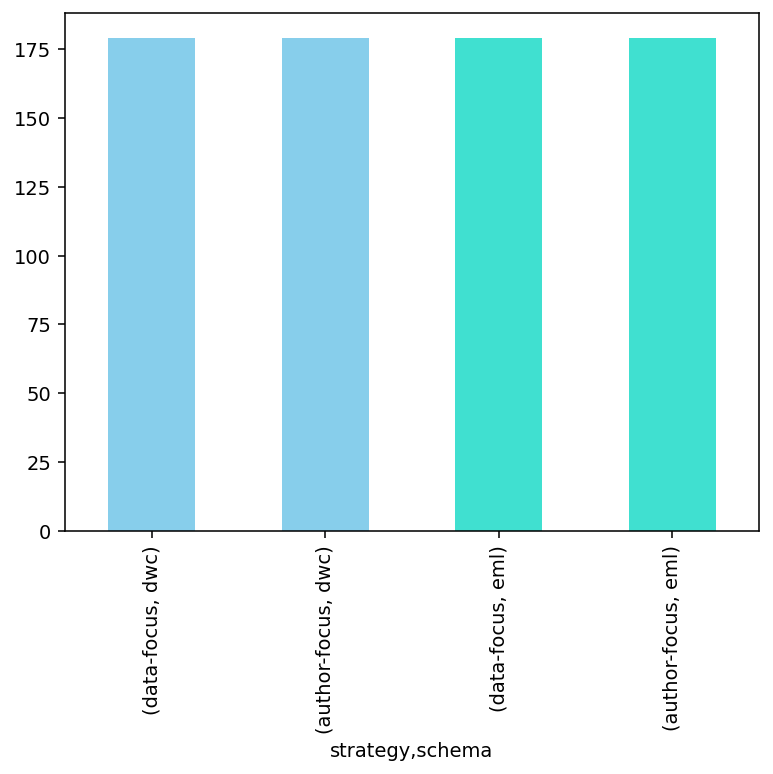

In [12]:
_ = experiment_log[['strategy', 'schema']].value_counts().plot(kind='bar', color=['skyblue','skyblue', 'turquoise', 'turquoise'])

> _Number of success and failures of experiments per strategy and schema_

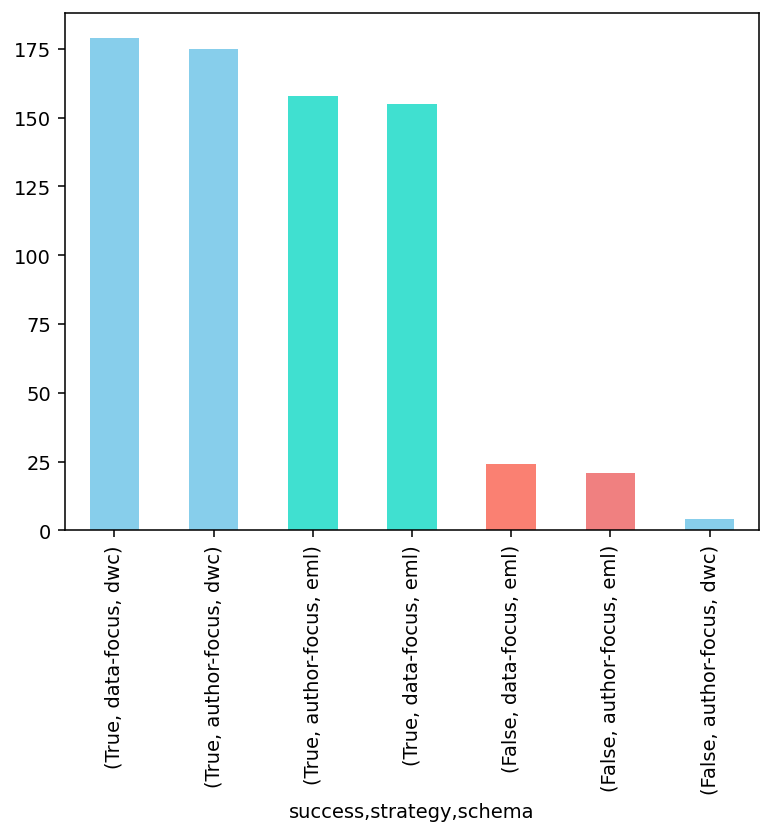

In [13]:
_ = experiment_log[['success', 'strategy', 'schema']].value_counts().plot(
    kind='bar', 
    color=['skyblue', 'skyblue', 'turquoise', 'turquoise', 'salmon', 'lightcoral']
)

> _Duration histogram (in minutes)_

Text(0.5, 0, 'Duration (minutes)')

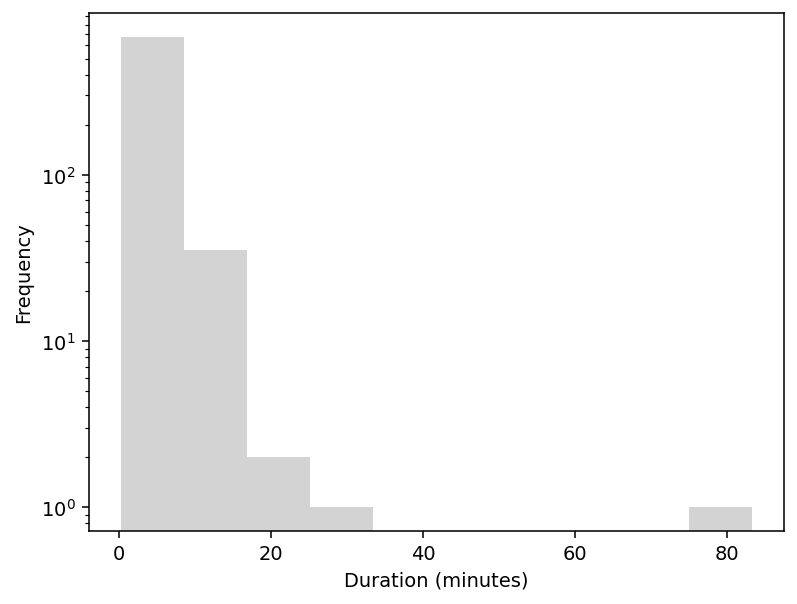

In [14]:
ax = (experiment_log["duration_seconds"] / 60).plot.hist(log=True, color="lightgray")
ax.set_xlabel("Duration (minutes)")

In [15]:
experiment_log["duration_minutes"] = (experiment_log["duration_seconds"] / 60)

> _Duration histogram of succeeded experiments (minutes)_

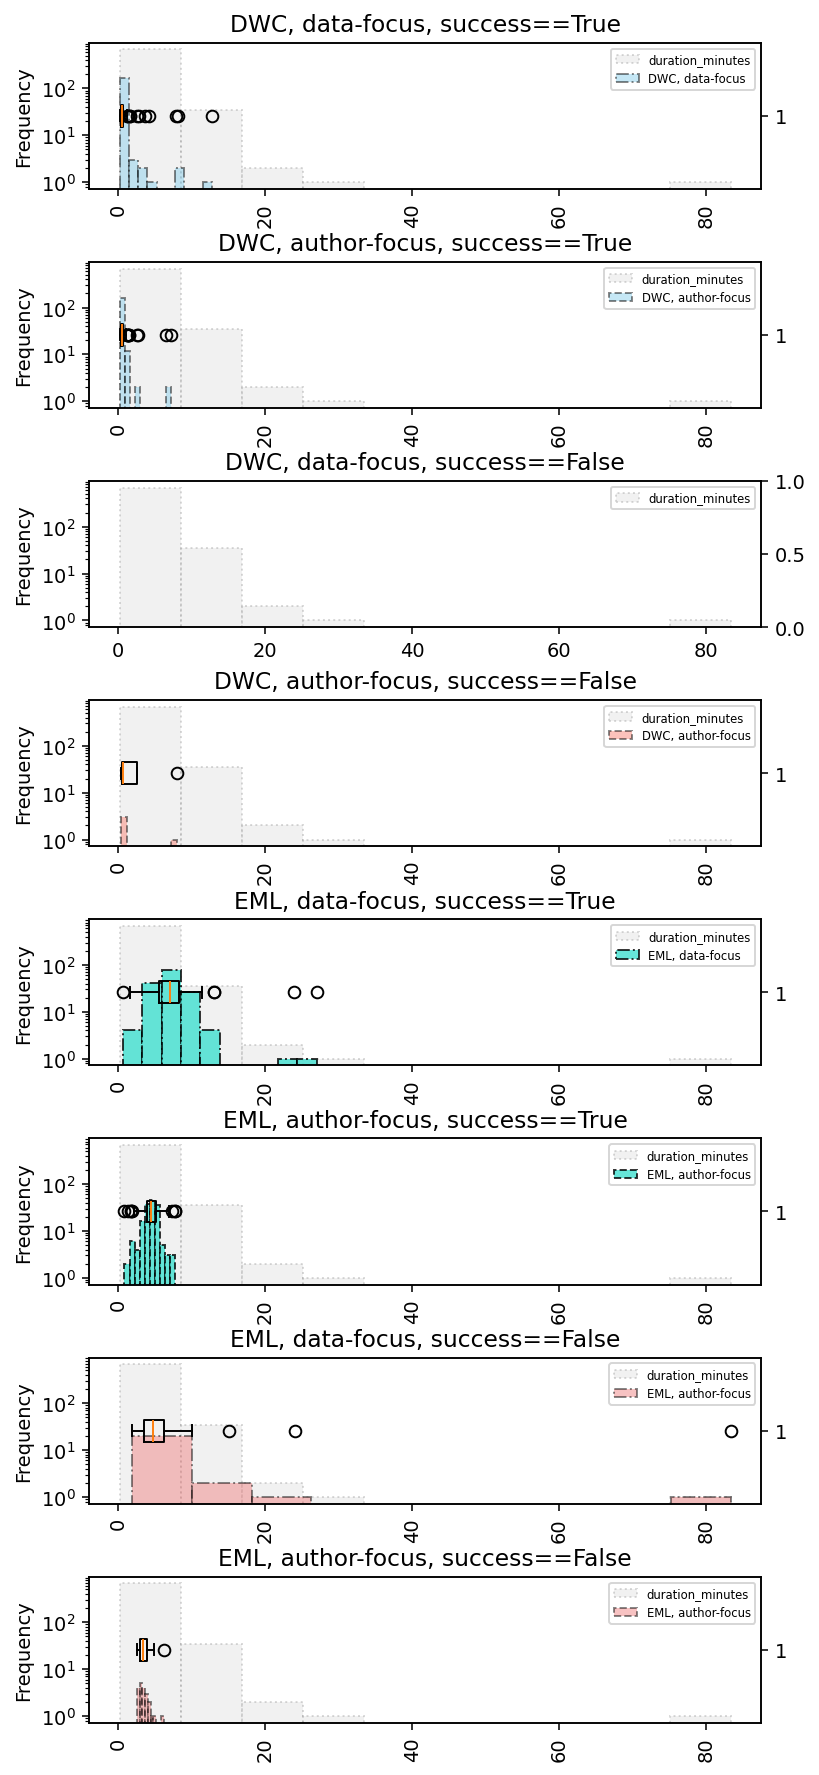

In [19]:
fig, axs = plt.subplots(8, 1, figsize=(6, 16))

for i in range(8):
    ax = axs[i]
    twax = ax.twinx()
    (experiment_log["duration_minutes"]).plot.hist(log=True, color="lightgray", alpha=0.3, legend=True, ls=":", edgecolor="grey", ax = ax)
    # dwc, OK
    if i == 0:
        xs = experiment_log[(experiment_log["schema"] == 'dwc') & (experiment_log["success"] == True) & (experiment_log["strategy"] == "data-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["skyblue"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="-.",
            label="DWC, data-focus",
            ax=ax
        )
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("DWC, data-focus, success==True")
    if i == 1:
        xs = experiment_log[(experiment_log["schema"] == 'dwc') & (experiment_log["success"] == True) & (experiment_log["strategy"] == "author-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["skyblue"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="--",
            label="DWC, author-focus",
            ax=ax
        )
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("DWC, author-focus, success==True")
    if i == 2:
        # dwc, FAILED
        xs = experiment_log[(experiment_log["schema"] == 'dwc') & (experiment_log["success"] == False) & (experiment_log["strategy"] == "data-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["salmon"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="-.",
            label="DWC, author-focus",
            ax=ax
        ) if xs.size else ...
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("DWC, data-focus, success==False")
    if i == 3:
        xs = experiment_log[(experiment_log["schema"] == 'dwc') & (experiment_log["success"] == False) & (experiment_log["strategy"] == "author-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["salmon"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="--",
            label="DWC, author-focus",
            ax=ax
        ) if xs.size else ...
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("DWC, author-focus, success==False")
    if i == 4:
        # eml
        xs = experiment_log[(experiment_log["schema"] == 'eml') & (experiment_log["success"] == True) & (experiment_log["strategy"] == "data-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'],
            color=["turquoise"],
            sharey=True,
            log=True,
            alpha=0.8,
            edgecolor="black",
            ls="-.",
            label="EML, data-focus",
            ax=ax
        )
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("EML, data-focus, success==True")
    if i == 5:
        xs = experiment_log[(experiment_log["schema"] == 'eml') & (experiment_log["success"] == True) & (experiment_log["strategy"] == "author-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["turquoise"],
            sharey=True,
            log=True,
            alpha=0.8,
            edgecolor="black",
            ls="--",
            label="EML, author-focus",
            ax=ax
        )
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("EML, author-focus, success==True")
    if i == 6:
        # eml, FAILED
        xs = experiment_log[(experiment_log["schema"] == 'eml') & (experiment_log["success"] == False) & (experiment_log["strategy"] == "data-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["lightcoral"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="-.",
            label="EML, author-focus",
            ax=ax
        ) if xs.size else ...
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("EML, data-focus, success==False")
    if i == 7:
        xs = experiment_log[(experiment_log["schema"] == 'eml') & (experiment_log["success"] == False) & (experiment_log["strategy"] == "author-focus")]
        _ = xs.hist(
            column='duration_minutes', 
            by=['schema'], 
            color=["lightcoral"],
            sharey=True,
            log=True,
            alpha=0.48,
            edgecolor="black",
            ls="--",
            label="EML, author-focus",
            ax=ax
        ) if xs.size else ...
        twax.boxplot(xs['duration_minutes'], vert=False) if xs.size else ...
        ax.set_title("EML, author-focus, success==False")
    _ = ax.legend(fontsize=6)
plt.savefig("duration-breakdown-minutes.png")
plt.show()

> _Duration histogram of failed experiments (minutes)_

array([[<Axes: title={'center': '(True, author-focus, dwc)'}>,
        <Axes: title={'center': '(True, author-focus, eml)'}>],
       [<Axes: title={'center': '(True, data-focus, dwc)'}>,
        <Axes: title={'center': '(True, data-focus, eml)'}>]],
      dtype=object)

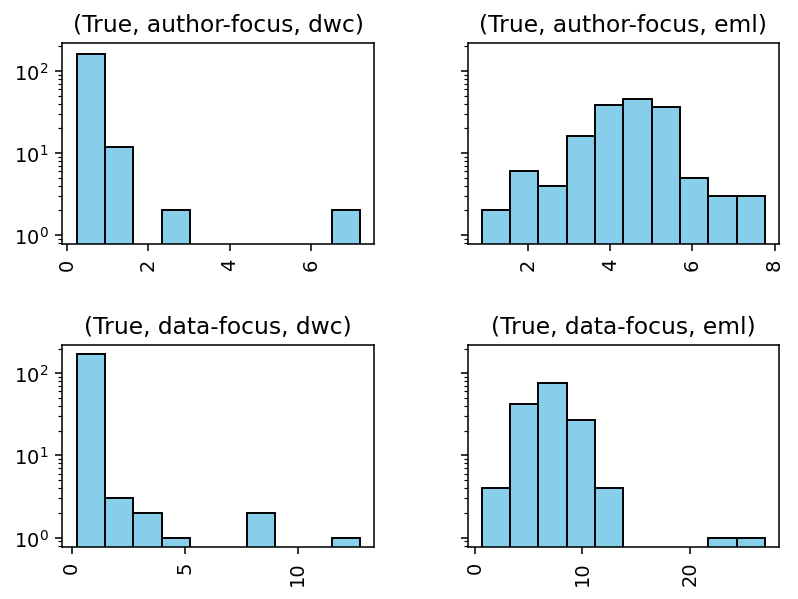

In [25]:
experiment_log[experiment_log["success"] == True].hist(
    column='duration_minutes', 
    by=['success', 'strategy', 'schema'], 
    color=["skyblue"],
    sharey=True,
    log=True,
    edgecolor="black",
    label="success == False",
    # ax=ax
)

array([[<Axes: title={'center': '(False, author-focus, dwc)'}>,
        <Axes: title={'center': '(False, author-focus, eml)'}>],
       [<Axes: title={'center': '(False, data-focus, eml)'}>, <Axes: >]],
      dtype=object)

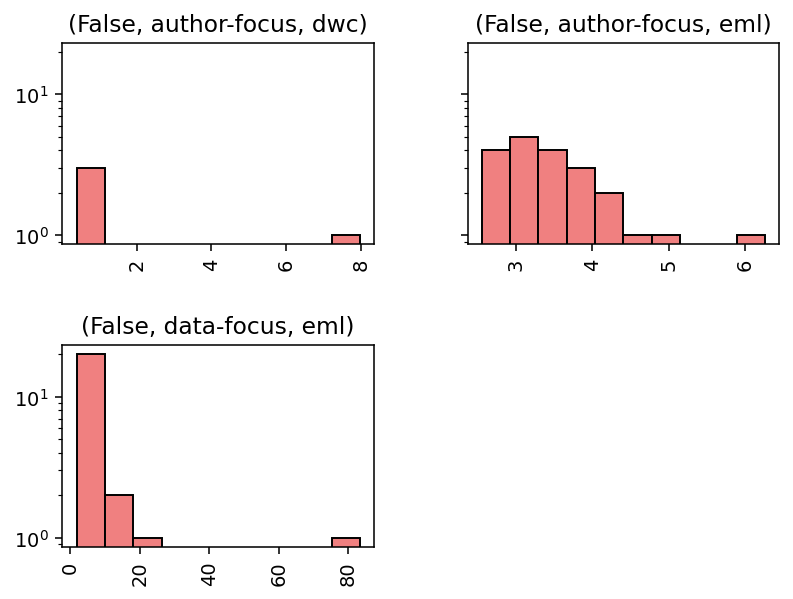

In [24]:
experiment_log[experiment_log["success"] == False].hist(
    column='duration_minutes', 
    by=['success', 'strategy', 'schema'], 
    color=["lightcoral"],
    sharey=True,
    log=True,
    edgecolor="black",
    label="success == False",
    # ax=ax
)

> _Example successful metadata_

In [19]:
first_experiment_metadata = next(experiment_log[["out_dir","working_copy_data_dir","ground_truth_metadata_dwc", "outcome_json"]].head(1).iterrows())

In [20]:
entries = first_experiment_metadata[1].tolist()
first_out_dir, first_working_copy_data, first_gt_metadata, first_outcome_json = list(map(grounded_path, entries[:3])) + [entries[3]]

In [21]:
list(first_working_copy_data.iterdir())

[PosixPath('../../_data/gbif_data_archive/working_copy/data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data/event.txt'),
 PosixPath('../../_data/gbif_data_archive/working_copy/data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data/occurrence.txt')]

> _Produced `meta.xml`_

In [22]:
import json

In [23]:
first_outcome = json.loads(first_outcome_json)

In [24]:
first_outcome_meta_xml = first_outcome["resolutions"][0]["working_copy_xml_blueprint"]["content"]
print(first_outcome_meta_xml)

<?xml version="1.0" encoding="UTF-8"?>
<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="meta.xml">
  <core rowType="http://rs.tdwg.org/dwc/terms/Occurrence" fieldsTerminatedBy="\t" fieldsEnclosedBy="&quot;" ignoreHeaderLines="1" encoding="UTF-8">
    <files>
      <location>occurrence.txt</location>
    </files>
    <id index="0" />
    <field index="1" term="http://rs.tdwg.org/dwc/terms/type" />
    <field index="2" term="http://rs.tdwg.org/dwc/terms/license" />
    <field index="3" term="http://rs.tdwg.org/dwc/terms/institutionID" />
    <field index="4" term="http://rs.tdwg.org/dwc/terms/collectionID" />
    <field index="5" term="http://rs.tdwg.org/dwc/terms/institutionCode" />
    <field index="6" term="http://rs.tdwg.org/dwc/terms/collectionCode" />
    <field index="7" term="http://rs.tdwg.org/dwc/terms/datasetName" />
    <field index="8" term="http://rs.tdwg.org/dwc/terms/basisOfRecord" />
    <field index="9" term="http://rs.tdwg.org/dwc/terms/occurrenceID" />
    <fie

> _Ground truth `meta.xml`_

In [25]:
first_gt_metadata_xml = first_gt_metadata.read_text()
print(first_gt_metadata_xml)

<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="eml.xml">
  <core encoding="UTF-8" fieldsTerminatedBy="\t" linesTerminatedBy="\n" fieldsEnclosedBy="" ignoreHeaderLines="1" rowType="http://rs.tdwg.org/dwc/terms/Event">
    <files>
      <location>event.txt</location>
    </files>
    <id index="0" />
    <field index="1" term="http://rs.tdwg.org/dwc/terms/eventID"/>
    <field index="2" term="http://rs.tdwg.org/dwc/terms/eventDate"/>
    <field index="3" term="http://rs.tdwg.org/dwc/terms/year"/>
    <field index="4" term="http://rs.tdwg.org/dwc/terms/month"/>
    <field index="5" term="http://rs.tdwg.org/dwc/terms/day"/>
    <field index="6" term="http://rs.tdwg.org/dwc/terms/habitat"/>
    <field index="7" term="http://rs.tdwg.org/dwc/terms/samplingProtocol"/>
    <field index="8" term="http://rs.tdwg.org/dwc/terms/sampleSizeValue"/>
    <field index="9" term="http://rs.tdwg.org/dwc/terms/sampleSizeUnit"/>
    <field index="10" term="http://rs.tdwg.org/dwc/terms/samplingEffort

In [26]:
from xmldiff import main

> _Quick overview of diffs_

In [27]:
main.diff_texts("\n".join(first_outcome_meta_xml.split("\n")[1:]), first_gt_metadata_xml)

[UpdateAttrib(node='/*[1]', name='metadata', value='eml.xml'),
 MoveNode(node='/*/*[1]', target='/*[1]', position=1),
 RenameNode(node='/*/*[1]', tag='{http://rs.tdwg.org/dwc/text/}core'),
 UpdateAttrib(node='/*/*[1]', name='fieldsEnclosedBy', value=''),
 InsertAttrib(node='/*/*[1]', name='linesTerminatedBy', value='\\n'),
 MoveNode(node='/*/*[1]/*[5]', target='/*/*[1]', position=14),
 MoveNode(node='/*/*[1]/*[5]', target='/*/*[1]', position=5),
 MoveNode(node='/*/*[1]/*[7]', target='/*/*[1]', position=14),
 MoveNode(node='/*/*[1]/*[18]', target='/*/*[1]', position=15),
 MoveNode(node='/*/*[1]/*[19]', target='/*/*[1]', position=19),
 MoveNode(node='/*/*[1]/*[22]', target='/*/*[1]', position=18),
 MoveNode(node='/*/*[1]/*[23]', target='/*/*[1]', position=26),
 MoveNode(node='/*/*[1]/*[25]', target='/*/*[1]', position=26),
 RenameNode(node='/*/*[2]', tag='{http://rs.tdwg.org/dwc/text/}extension'),
 UpdateAttrib(node='/*/*[2]', name='fieldsEnclosedBy', value=''),
 InsertAttrib(node='/*/*[

In [28]:
from xmldiff import formatting

formatter = formatting.XMLFormatter(normalize=formatting.WS_BOTH)
print(main.diff_texts("\n".join(first_outcome_meta_xml.split("\n")[1:]), first_gt_metadata_xml, formatter=formatter))

<archive xmlns="http://rs.tdwg.org/dwc/text/" xmlns:diff="http://namespaces.shoobx.com/diff" metadata="eml.xml" diff:update-attr="metadata:meta.xml">
  <core rowType="http://rs.tdwg.org/dwc/terms/Occurrence" fieldsTerminatedBy="\t" fieldsEnclosedBy="&quot;" ignoreHeaderLines="1" encoding="UTF-8" diff:delete="">
    <files>
      <location>occurrence.txt</location>
    </files>
    <id index="0"/>
    <field index="1" term="http://rs.tdwg.org/dwc/terms/type"/>
    <field index="2" term="http://rs.tdwg.org/dwc/terms/license"/>
    <field index="3" term="http://rs.tdwg.org/dwc/terms/institutionID"/>
    <field index="4" term="http://rs.tdwg.org/dwc/terms/collectionID"/>
    <field index="5" term="http://rs.tdwg.org/dwc/terms/institutionCode"/>
    <field index="6" term="http://rs.tdwg.org/dwc/terms/collectionCode"/>
    <field index="7" term="http://rs.tdwg.org/dwc/terms/datasetName"/>
    <field index="8" term="http://rs.tdwg.org/dwc/terms/basisOfRecord"/>
    <field index="9" term="http

In [29]:
!pip install xmltodict dictdiffer

In [30]:
import xmltodict
from dictdiffer import diff
from IPython.display import HTML, display

def display_data_diff(xml_old, xml_new):
    # 1. Convert XML strings to nested dictionaries
    # process_namespaces=True handles the 'dwc' prefixes properly
    dict_old = xmltodict.parse(xml_old)
    dict_new = xmltodict.parse(xml_new)

    # 2. Calculate the difference
    result = list(diff(dict_old, dict_new))

    # 3. Build a stylized HTML table for the results
    rows = []
    for change_type, path, values in sorted(result, key=lambda vs: str(vs[1]), reverse=True):
        # Format the path for readability (e.g., archive.core.field[0])
        path_str = ".".join([str(p) for p in path]) if isinstance(path, list) else str(path)
        
        if change_type == 'change':
            old_val, new_val = values
            rows.append(f"""
                <tr class='row-update'>
                    <td><b>UPDATE</b></td>
                    <td><code>{path_str}</code></td>
                    <td><del>{old_val}</del> <ins>{new_val}</ins></td>
                </tr>""")
        elif change_type == 'add':
            for attr, val in values:
                rows.append(f"""
                    <tr class='row-add'>
                        <td><b>INSERT</b></td>
                        <td><code>{path_str} → {attr}</code></td>
                        <td>{val}</td>
                    </tr>""")
        elif change_type == 'remove':
            for attr, val in values:
                rows.append(f"""
                    <tr class='row-remove'>
                        <td><b>DELETE</b></td>
                        <td><code>{path_str} → {attr}</code></td>
                        <td><del>{val}</del></td>
                    </tr>""")

    # 4. Define the UI Template
    style = """
    <style>
        .diff-table { width: 100%; border-collapse: collapse; font-family: sans-serif; font-size: 13px; }
        .diff-table th { background: #f6f8fa; text-align: left; padding: 10px; border-bottom: 2px solid #d0d7de; }
        .diff-table td { padding: 8px; border-bottom: 1px solid #eee; vertical-align: top; }
        code { color: goldenrod; font-weight: bold; }
        .row-update { background-color: #fff8c5; }
        .row-add { background-color: #dafbe1; }
        .row-remove { background-color: #ffebe9; }
        del { color: #cf222e; text-decoration: line-through; }
        ins { color: #1a7f37; text-decoration: none; font-weight: bold; }
    </style>
    """
    
    table_html = f"""
    {style}
    <table class='diff-table'>
        <thead>
            <tr><th>Action</th><th>Path in Metadata</th><th>Change (Old vs New)</th></tr>
        </thead>
        <tbody>
            {"".join(rows) if rows else "<tr><td colspan='3'>No differences found.</td></tr>"}
        </tbody>
    </table>
    """
    
    display(HTML(table_html))

# Usage
display_data_diff(first_outcome_meta_xml, first_gt_metadata_xml)

Action,Path in Metadata,Change (Old vs New)
UPDATE,archive.extension.files.location,event.txt occurrence.txt
DELETE,archive.extension.field → 26,"{'@index': '26', '@term': 'http://rs.tdwg.org/dwc/terms/georeferenceSources'}"
DELETE,archive.extension.field → 25,"{'@index': '25', '@term': 'http://rs.tdwg.org/dwc/terms/coordinatePrecision'}"
UPDATE,archive.extension.coreid.@index,11 0
UPDATE,archive.extension.@rowType,http://rs.tdwg.org/dwc/terms/Event http://rs.tdwg.org/dwc/terms/Occurrence
UPDATE,archive.extension.@fieldsEnclosedBy,""""
INSERT,archive.extension → @linesTerminatedBy,\n
UPDATE,archive.core.files.location,occurrence.txt event.txt
INSERT,archive.core.field → 25,"{'@index': '26', '@term': 'http://rs.tdwg.org/dwc/terms/georeferenceSources'}"
UPDATE,archive.core.@rowType,http://rs.tdwg.org/dwc/terms/Occurrence http://rs.tdwg.org/dwc/terms/Event


In [31]:
from lxml import etree

def xml_structural_similarity(xml_a, xml_b):
    def get_structural_fingerprint(xml_str):
        # Strip declaration to prevent parsing errors
        xml_data = xml_str.encode() if isinstance(xml_str, str) else xml_str
        parser = etree.XMLParser(remove_blank_text=True)
        root = etree.fromstring(xml_data, parser)
        tree = root.getroottree()
        
        # We collect the path of every node to represent the tree's shape
        # getpath(n) returns strings like '/archive/core/field[1]'
        return {tree.getpath(n) for n in root.iter()}

    try:
        paths_a = get_structural_fingerprint(xml_a)
        paths_b = get_structural_fingerprint(xml_b)
        
        intersection = len(paths_a & paths_b)
        union = len(paths_a | paths_b)
        
        return intersection / union if union > 0 else 1.0
    except Exception as e:
        return f"Error calculating similarity: {e}"

# Usage
score = xml_structural_similarity(first_outcome_meta_xml, first_gt_metadata_xml)
print(f"Structural Similarity Score: {score=}")

Structural Similarity Score: score=0.9516129032258065


In [32]:
from lxml import etree
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def sklearn_xml_structural_similarity(xml_a, xml_b):
    def get_structure_as_string(xml_str):
        """Converts XML into a string of tags to represent its skeleton."""
        parser = etree.XMLParser(remove_blank_text=True)
        root = etree.fromstring(xml_data := xml_str.encode() if isinstance(xml_str, str) else xml_str, parser)
        # We join all tags in order. Example: "archive core files location field field..."
        return " ".join(node.tag.split('}')[-1] for node in root.iter())

    # 1. Represent XMLs as structural "prose"
    struct_a = get_structure_as_string(xml_a)
    struct_b = get_structure_as_string(xml_b)

    # 2. Vectorize the structures using 2-grams and 3-grams
    # Using n-grams captures local parent-child and sibling-sibling relationships
    vectorizer = TfidfVectorizer(ngram_range=(1, 3), analyzer='word')
    tfidf_matrix = vectorizer.fit_transform([struct_a, struct_b])

    # 3. Calculate Cosine Similarity
    # This measures the cosine of the angle between the two structural vectors
    score = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])
    
    return score[0][0]

# Usage
score = sklearn_xml_structural_similarity(first_outcome_meta_xml, first_gt_metadata_xml)
print(f"Scikit-Learn Structural Similarity (Cosine): {score:.4f}")

Scikit-Learn Structural Similarity (Cosine): 1.0000


In [33]:
from lxml import etree
import collections

def nierman_jagadish_similarity(xml_a, xml_b):
    def get_subtrees(root):
        """
        Decomposes the tree into a multiset of subtree signatures (Nierman & Jagadish approach).
        Each signature represents a structural unit.
        """
        signatures = []
        for node in root.iter():
            # Create a localized structural signature for the subtree starting at this node
            # Format: (tag, (child_tag1, child_tag2, ...))
            children_tags = tuple(child.tag for child in node)
            signature = (node.tag, children_tags)
            signatures.append(signature)
        return collections.Counter(signatures)

    try:
        # Parse and clean
        parser = etree.XMLParser(remove_blank_text=True)
        root_a = etree.fromstring(xml_a.encode() if isinstance(xml_a, str) else xml_a, parser)
        root_b = etree.fromstring(xml_b.encode() if isinstance(xml_b, str) else xml_b, parser)

        # 1. Generate Structural Signatures (multisets)
        stats_a = get_subtrees(root_a)
        stats_b = get_subtrees(root_b)

        # 2. Calculate the Intersection (Common subtrees)
        common_count = 0
        all_keys = set(stats_a.keys()) | set(stats_b.keys())
        
        for key in all_keys:
            # Nierman & Jagadish looks at the minimum overlap of structural units
            common_count += min(stats_a[key], stats_b[key])

        # 3. Structural Similarity Formula:
        # 2 * CommonNodes / (TotalNodes_A + TotalNodes_B)
        total_a = sum(stats_a.values())
        total_b = sum(stats_b.values())
        
        similarity = (2.0 * common_count) / (total_a + total_b)
        return similarity

    except Exception as e:
        return f"Error: {e}"

# Test with your metadata
score = nierman_jagadish_similarity(first_outcome_meta_xml, first_gt_metadata_xml)
print(f"Nierman-Jagadish Structural Similarity: {score:.4f}")

Nierman-Jagadish Structural Similarity: 0.9587
